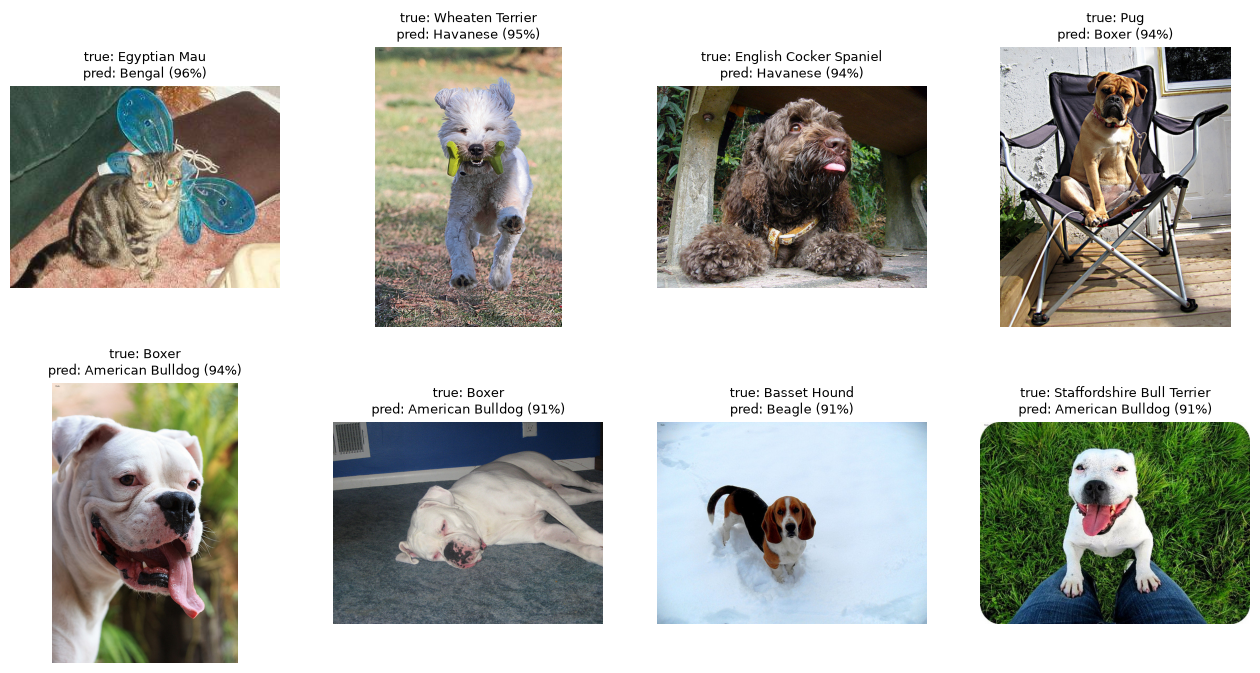

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision.datasets import OxfordIIITPet

d = np.load("../reports/resnet18_feature_extract_test_preds.npz")
probs, labels = d["probs"], d["labels"]
preds = probs.argmax(1)

raw = OxfordIIITPet(Path("../data"), split="test", target_types="category")
wrong = np.where(preds != labels)[0]
wrong = wrong[np.argsort(-probs[wrong, preds[wrong]])][:8]  # most confident mistakes

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.flat, wrong):
    img, _ = raw[int(i)]
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(f"true: {raw.classes[labels[i]]}\npred: {raw.classes[preds[i]]} ({probs[i, preds[i]]:.0%})",
                 fontsize=9)
plt.show()

 Error Analysis (შეცდომების ანალიზი)

მთავარი მიგნება: მოდელი ძირითადად ცდება ვიზუალურად ძალიან მსგავს ჯიშებზე (Boxer vs Bulldog, Basset Hound vs Beagle, Ragdoll vs Birman). 

მიზეზი: 224x224 რეზოლუციაზე პატარა დეტალები იკარგება (მაგ. ბასეტის ფეხების სიგრძე ან კატის ბეწვის ტექსტურა).

გაუმჯობესების გზები (მომავლისთვის):
1. უფრო მაღალი რეზოლუციის გამოყენება (მაგ. 384x384).
2. ამ კონკრეტული ჯიშებისთვის მეტი მონაცემის მოძიება.
3. მონაცემების უფრო აგრესიული Augmentation (მაგ. CutMix).